# 🎛️ From Cost of Carry to Risk Control and Synthetic Positions

The cost of carry equation we developed in Chapter Two doesn't just describe how spot prices drive futures prices—it provides the mechanical foundation for using futures to control portfolio risk. To make the jump from theory to application, we need to modify our baseline equation to explicitly include the real-world friction: the arbitrage band ($\Delta_t$).

$$F_t = S_t\times\left(1+(r_t+\Delta_t)\times\frac{T-t}{360}\right) - FVD_t$$

Where $t$ is the current date, $r_t$ is the forward rate of interest, $\Delta_t$ is the dynamic arbitrage band discussed in Chapter Two, $FVD_t$ is the total future value of all dividends paid before expiration, and $T$ is the contIract expiration date

> **💡 What is $\Delta_t$? (The Directional Friction)**
>
> As discussed in Chapter Two, the $t$ subscript matters because market friction is a moving target. Crucially, $\Delta_t$ is not a fixed premium—it can be **positive or negative** depending on the dominant flow of traffic.
>
> In ordinary times, the directional flow of arbitrage is balanced, and $\Delta_t$ sits tightly around baseline costs. A prime broker might finance a cash position for 25-50 bps over SOFR, while the cost to borrow an S&P 500 stock quietly sits between 10-30 bps. But when market sentiment aggressively flips, the demand becomes entirely one-sided:
>
> * **Risk-On (Positive Friction):** When the market is surging, futures get expensive. Arbitrageurs execute Cash & Carry (buying the index, shorting the futures) and need to borrow massive amounts of cash. Prime brokers hike their lending rates to ration balance sheet capacity, driving $\Delta_t$ sharply higher.
> * **Risk-Off (Negative Friction):** When the market panics, futures get cheap. Arbitrageurs execute Reverse Cash & Carry (buying the futures, shorting the index) and need to locate and borrow the underlying equities of all 500 companies. Those 10-30 bps stock borrow fees suddenly balloon as demand surges. Combined with plummeting cash reinvestment rates, this creates a massive drag, pulling $\Delta_t$ lower (or deeply negative relative to the benchmark).
>
> The financial infrastructure doesn't just constrict; it tilts. The arbitrage bands dramatically widen in the specific direction of the market stress, right when the theoretical mispricings are largest.

## 🧮 Risk and the Relation Between Future and Spot Prices: Verifying the Mathematics

In Chapter Two, we used the first-order Taylor approximation to simplify the cost of carry equation:

$$(1 + (r_t+\Delta_t)\times \frac{T-t}{360})^{-1} \simeq(1 - (r_t+\Delta_t) \times \frac{T-t}{360})$$

$$S_t=(F_t+FVD_t)\times(1 + (r_t+\Delta_t)\times \frac{T-t}{360})^{-1} \simeq (F_t+FVD_t)\times(1 - (r_t+\Delta_t) \times \frac{T-t}{360})$$

The approximation makes it easy to conceptualize how a \$1 change in the spot market ($S$) ripples through to the futures price ($F$). To do this, we take the derivative of both sides with respect to $S$. For the front-month S&P 500 Mini contracts, it's unlikely that the future value of dividends or forward rates are strongly related to the level of the index. As a result, we will assume that:

$$\frac{\partial r_t}{\partial S_t} = 0 \quad \text{and} \quad \frac{\partial FVD_t}{\partial S_t} = 0$$

Notice that we are not assuming that $\large\frac{\partial \Delta_t}{\partial S_t} = \normalsize 0$. In Chapter Two, we noted that trading Crude Oil or Corn futures included an implicit side bet on pipelines, storage tanks, grain elevators, and barges. That point is repeated here in a more subtle way.

Differentiating the cost of carry equation with respect to the spot price ($S_t$) reveals that the financing advantage of futures results in a slightly higher absolute point volatility than the stock market. But that volatility is enhanced or moderated by changes in the arbitrage band ($\Delta_t$).

$$ \frac{\partial F_t}{\partial S_t} - \frac{\partial F_t}{\partial S_t} \times (r_t+\Delta_t) \times \frac{T-t}{360} - (F_t+FVD_t) \times \frac{\partial \Delta_t}{\partial S_t} \times \frac{T-t}{360} \simeq 1 $$

Although it's tempting to think that there is a one-to-one relation between changes in futures and spot prices, the derivation demonstrates something important: changes in futures prices are amplified by the financing effect, but that effect is enhanced or ameliorated by the arbitrage band.

To match a movement in the spot price, the futures price has to be scaled by the financing advantage and the arbtrage band. But that moving target is itself a random variable. The result is that attempts to alter a portfolio's risk will always be an approximation.

All this flows from the cost of carry equation developed in Chapter Two: a direct application of the math working in real-time.


:::{dropdown}💡 <b>Are we assuming stock price changes are unrelated to interest rates and dividends?</b>

Assuming that $\frac{\partial r_t}{\partial S_t} = 0$ and $\frac{\partial FVD_t}{\partial S_t} = 0$, does not mean interest rates and dividend payouts are constant. They do fluctuate over time, and those fluctuations will cause the futures price to drift independently of the changes in the S&P 500 (so-called basis risk). For the purpose of calculating our instantaneous hedge ratio—how many contracts we need to buy or sell to neutralize a move in the S&P 500 today—it's safe to assume that a sudden jump in the equity index does not trigger an immediate change in the SOFR rate. In the long run, changes in dividends are correlated with changes in the index. For the front-month S&P contract, dividends are largely determined, and that cross-partial is safely ignored.
:::

## 📍 Notebook Roadmap
### ⚖️ First Objective: Relating Arbitrage Bands to Market Risk

The arbitrage band is not directly observed but can be inferred from the discrepancy between synthetic and cash market returns. **For example, a synthetic-long S&P 500 position (holding long futures and earning SOFR in a money market account) should theoretically match the cash index return.** If the synthetic-long return exceeds the cash return, the futures are **"cheap"** and $\Delta_{t-1}$ is negative. The synthetic-short returns (**holding the cash index and shorting futures**) are the mirror image: cheap futures result in synthetic money market returns that are less than SOFR.

The cost of carry equation suggests that the futures position should account for both forward SOFR and the arbitrage band. The return from $t-1$ to $t$ should be adjusted by the following factor:
$$1 - (R_{t-1}^{\text{forward}}+\Delta_{t-1})\times\frac{T-t+1}{360}$$
where $R_{t-1}^{\text{forward}}$ is the forward rate, $\Delta_{t-1}$ is the arbitrage band, and $T-t+1$ is the number of days remaining until expiration.

We will measure the impact of $\Delta_t$ by comparing the synthetic and cash returns. These discrepancies will then be related to measures of market risk using the VIX index. The so-called "risk-on" and "risk-off" periods will be defined by comparing the VIX to 16.5 (it median value for the three period ending on September 16, 2026).


<details>
<summary>💡 <b>What is the VIX?</b></summary>
The Cboe Volatility Index (VIX) measures the market's expectation of 30-day forward-looking volatility, derived from S&P 500 options. Often referred to as the "fear gauge," a VIX reading above its median typically signals elevated uncertainty (risk-off), while a reading below the median suggests market stability (risk-on).

<a href='https://www.cboe.com/tradable-products/vix/vix-options'>CBOE Description</a>
</details>

### 🏗️ Second Objective: Applying Cost of Carry to Portfolio Construction

Our next objective is to demonstrate how the S&P 500 contract can be used to mathematically create—and mostly eliminate—market risk. Because the futures contract is tethered to the spot market by the cost of carry, we can use it to build two perfectly inverse static portfolios.

📈 **Heads: The Synthetic Long (Creating Risk)**

An investor wants $\$100 \text{ million}$ of exposure to the S&P 500 but wants to keep their cash perfectly liquid. Instead of buying a basket of individual stocks in the index, they invest the $\$100 \text{ million}$ in an overnight SOFR money market account.

To synthesize the equity exposure, they go long S&P 500 futures. The amplified volatility of futures results in a scaled-down futures position. Instead of a full $\$100 \text{ million}$ worth of contracts, the position is adjusted to account for the financing advantage:

$$\text{Target Futures Exposure} = \$100,000,000 \times \left(1-(r_t+\Delta_t) \times \frac{T-t}{360}\right)$$

By definition, this futures position will deliver the exact dollar-for-dollar returns of the index in excess of the implied repo rate. How closely this tracks the *actual* cash market depends entirely on our side bet: the shifting arbitrage band ($\Delta_t$). Nevertheless, the main engine of risk and return remains exactly where we want it—in the price changes of the S&P 500.

**🛡️ Tails: The Implied Repo (Eliminating Risk)**

An investor currently holds a $\$100 \text{ million}$ S&P 500 ETF but believes the market is about to crash. They want to move to cash without selling their shares and triggering a massive tax bill. To synthesize a cash position, they hold the ETF and short the S&P 500 futures.

Again, using our scaling factor, they short slightly less than $\$100 \text{ million}$ worth of futures. By neutralizing the instantaneous price sensitivity (the derivative $\frac{\partial F_t}{\partial S_t}$), the investor largely insulates the portfolio against a sudden $20\%$ market drop. Keep in mand that this scaling factor is a moving target. The portfolio's value at expiration $T$ is stabilized, but not locked in.

By shorting the futures against the spot position, the investor has transformed their volatile equity portfolio into a synthetic money market instrument. The rate of return on this hedged portfolio is known as the **Implied Repo Rate**. The arbitrage band ($\Delta_t$) will cause it to differ from SOFR ($r_t$).

> **Key Insight:** If equity investors treat the implied repo rate ($r_t + \Delta_t$) as their true, executable opportunity cost of cash, then this fluctuating friction ($\Delta_t$) is already embedded in the cash market's pricing ($S_t$). If so, the financing "advantage" of the futures is not an anomaly; it is simply the true risk-free rate of the equity market.

 **🪙 Rigging the Toss: From Static to Dynamic**

Both Heads and Tails share a key feature: they are static hedges. The coin is placed on the table, and the position is held to expiration.

But what if an investor wants to rig the toss? What if they want to capture the upside of Heads, while eliminating some of the downside risk of Tails? A static hedge is not sufficient. Dynamic rules are needed. This brings us to the concepts and mechanics of Portfolio Insurance.

In practice, dynamic hedging relies on complex options pricing models to calculate exact exposure adjustments. In this notebook, we will skip the Black-Scholes calculus and use a simple, intuitive heuristic. Keep a close eye on the cost of the dynamic hedge. As we'll discover in the *Options* volume, this cost is the exact price of an option—just paid out in slow motion.


## 📊 The Next Step: From Theoretical Mathematics to Market Data

It is time to move from theory to application. Before we can relate arbitrage bands to market risk or calierate or synthetic portfolios, we need to construct our baseline static portfolios: the synthetic long S&P 500 and the synthetic money market. Here is the data and the mechanical roll logic required to build them:

1. **Scaling Futures:** The arbitrage band ($\Delta_t$) is unknown, but as in Chapter Two, we can infer forward rates from SOFR futures. Using this simplification, we can back out the effect of $\Delta_t$ from the data.

2. **Stitching Together Contracts:** We will conduct our experiment for one year, beginning on September 16, 2025. The near-term contracts will be rolled on the second Thursday of the expiration month. The roll direction depends on the portfolio:
   * **Synthetic Long:** Sell the expiring near-term contract and buy the next-out contract.
   * **Synthetic Money Market (Implied Repo):** Buy the expiring near-term contract to cover, and short the next-out contract.

3. **Required Data:**
   * **SOFR Index:** Used to calculate SOFR rates and forward rates, accessed from FRED using `FredReader`.
   * **VIX Index:** Calibrates market risk and is accessed from FRED using `FredReader`.
   * **Forward Rates:** Needed to scale the number of contracts for each date, accessed from MASSIVE using `MASSIVEReader` (contracts are September 2025, December 2025, March 2026, and June 2026).
   * **Futures Gains and Losses:** Calculated from changes in the settlement prices of the E-mini S&P 500 contracts, accessed from MASSIVE using `MASSIVEReader` (contracts are December 2025, March 2026, June 2026, and September 2026).
   * **S&P 500 Returns:** The total return for the S&P 500 index, accessed using the `static_futures_data` method from `financial_quant`.

## 📦 Getting Functions, Libraries, and Modules from financial_quant package

<details>
<summary><b style="font-size:1.2em; color: #1976d2; cursor: pointer;"><span style="font-size: 1.4em;">⚡🔌</span> Professional Packaging: How GitHub Installations Work</b></summary>
<br>
<p><b>The Logic:</b><br>
Usually, Python looks for modules as <code>.py</code> files on your hard drive. Here, we are "tricking" Python into treating a string of text from a URL as a live library updater script.</p>

<p><b>The Workflow:</b></p>
<ol>
<li><b>Fetch & Build:</b> The <code>urllib</code> script downloads and executes <code>fq_updater.py</code>, which verifies local dependency versions (like locking Pandas to 2.2.3) and installs or updates the <code>financial_quant</code> package in the background.</li>
<li><b>Import:</b> <code>fq = import_financial_quant()</code> loads the verified package into your notebook's memory and assigns it the quick alias <code>fq</code>.</li>
<li><b>Routing:</b> Behind the scenes, a special file called <code>__init__.py</code> acts as the package's "front door." It automatically gathers complex tools from deeply nested folders (like our fixed-income models and chart visualizers) and serves them up directly to the surface.</li>
<li><b>Execute:</b> You don't have to worry about where the files live. You just type <code>fq.create_arb_vix()</code> or <code>fq.plot_contract_arb_band()</code>, and Python immediately knows where to route the request.</li>
</ol>

<p><b>Why do this?</b><br>
The most important reason is to ensure these notebooks are environment-agnostic—whether you are using Jupyter Lab, Google Colab, or classic Jupyter Notebooks. Using the <code>financial_quant</code> package allows us to align all software versions and interpolation rules across machines. The package installs and manages the libraries; you only have to import them.</p>
</details>

In [1]:
# Use Python's built-in urllib to fetch the remote setup script
import urllib.request

# Download the script from GitHub, decode it into text, and execute it directly in memory.
# This "tricks" Python into running the updater without needing a local .py file.
updater_url = "https://raw.githubusercontent.com/PatrickJHess/quant_repo/master/fq_updater.py"
exec(urllib.request.urlopen(updater_url).read().decode('utf-8'))

# Run the installer/updater function and alias the package as 'fq'
fq = import_financial_quant()

# Import the core data libraries that the package just ensured are safely installed
import pandas as pd
import numpy as np


⚠️ Update found! (Local: 0.0.3 ➡️ Latest: 0.0.4)
🔄 Automatically updating financial_quant. Please wait...
✅ Process complete!
😕 Note: If newly updated charts or models don't look right, please Restart the Kernel.
*(Go to `Kernel` ➡️ `Restart Kernel and Run up to Selected Cell...`)*


## 🚰 Futures, the SOFR Index, SP 500 Total Returns Index, and Spot Prices: A Job For Our Data Pipelines

We will use three custom data pipelines—`FredReader`,`MASSIVEReader`, and `static_futures_data`--to pull the necessary data for this notebook. All three are included in the `financial_quant` package that we imported earlier as `fq`.

To divide and conquer the workload, we will instantiate two specific data objects:

* `fred_data`: Powered by `FredReader`, this fetches the SOFR and VIX Indexes as well as the spot price of the S&P 500.
*  `massive_data`: Powered by `MASSIVEReader`, this serves as our primary engine for downloading the daily futures contract data.
* `static_futures_data`: This module supplies the S&P 500 Daily Rates of Return needed for our baseline calculations.

In [2]:
# Instantiate the data pipelines from the financial_quant package
fred_data = fq.FredReader()
massive_data = fq.MASSIVEReader(calls_per_minute=5)
static_futures_data=fq.static_futures_data

📂 Cache anchored at: /home/pat/fred
✅ Key loaded securely from local vault ('.fred_key')
📂 Cache anchored at: /home/pat/massive_data
✅ Key loaded securely from local vault ('.massive')


## 📥 Getting SOFR & VIX Indexes and S&P 500 Spot Price

The SOFR Index & VIX  are loaded from FRED via `fred_data.get_series` using the following fallback sequence:

1. **Local Cache:** Validates local data against freshness rules (re-querying if last access was >7 days ago).
2. **Static Data:** Checks pre-packaged static data if local cache misses.
3. **Live API Call:** Queries the FRED API directly if neither cache layer fulfills the request.

The same hierach is followed for MASSIVE data and static data.

In [4]:
# Pull base data (Note: VIX requires extra historical data to calculate the 3-year median)
sofr_index = fred_data.get_series('SOFRINDEX', start_date='2025-09-16')
vix = fred_data.get_series('VIXCLS', start_date='2023-09-16')
spot_price = fred_data.get_series('SP500', start_date='2025-09-16',end_date='2026-09-16')


☁️--- Processing SOFRINDEX ---
🕒 Metadata is fresh (0 days old).
✅ Loaded SOFRINDEX from local Parquet cache.

☁️--- Processing VIXCLS ---
🕒 Metadata is fresh (0 days old).
✅ Loaded VIXCLS from local Parquet cache.

☁️--- Processing SP500 ---
🕒 Metadata is fresh (0 days old).
✅ Loaded SP500 from local Parquet cache.


### ⏱️ Calculating Forward Rates

There are a few things to keep in mind when we calculate the forward rate used to scale the S&P futures contract.

* **Gain From $t-1$ to $t$:** The gain is scaled by the forward rate when the contract was initiated at $t-1$, not at $t$.

    $$\left(1 - (r_{t-1}+\Delta_t) \times \frac{T-t+1}{360}\right)\times (F_t-F_{t-1})$$
    Where $T$ is the contract expiration date.

* **Reference Period:** SOFR rates are announced with a one-day delay. Until one day after the reference period begins, the forward rate is inferred from the closing futures price. After that date, the forward rate is calculated as:

   $$R^{forward}_{k} = \left( \left(1 + R^{futures}_{k} \times \frac{N}{360}\right) \times \large\frac{\text{SOFR Index}_{0}}{\text{SOFR Index}_{k}} - 1 \right) \times \large\frac{360}{N-k}$$

  Where $k$ is a day in the reference period ($1$ to $N-1$), $N$ is the total calendar days in the reference period, and $0$ is the first day of the reference period.
    
     *(Note: At day $0$, the formula mathematically collapses so that the forward rate simply equals the futures rate: $R^{forward}_0 = R^{futures}_0$)*.



## 📅 3-Month SOFR Futures Data

The futures data is accessed from MASSIVE. The `massive_data.get_futures_data` method follows the exact same three-step retrieval hierarchy of `fred_data.get_series`.

### 🗺️ Contract Mapping & Roll Dates
Because our starting date is September 16, 2025, the timeline maps to the SOFR futures contracts as follows:

* **Initial Period:** The first reference period runs from September 17 through December 16, 2025, which is covered by the September 2025 contract.

* **Active Dates:** The September contract governs the period from September 16 up to December 10, 2025 (the day before the December 11 roll date).

* **Subsequent Contracts:** The remaining three contracts start exactly on their respective roll dates and end the day before the following roll date.

### ⚖️ The ($t-1$) Scaling Rule
As a reminder, the daily gain or loss on the S&P 500 contract is always scaled using the forward rate from the day before ($t-1$).


---


>**Example:** The gain or loss on the December 11, 2025 roll date is calculated using the September contract and the forward rate active on December 10.

In [7]:
# Get three-month rates for the reference periods from Massive.com
sofr_sep = massive_data.get_futures_data('SR3U5', '2025-09-16', '2025-12-10')  # Sep 25 Contract
sofr_dec = massive_data.get_futures_data('SR3Z5', '2025-12-11', '2026-03-11')  # Dec 25 Contract
sofr_mar = massive_data.get_futures_data('SR3H6', '2026-03-12', '2026-06-10')  # Mar 26 Contract
sofr_jun = massive_data.get_futures_data('SR3M6', '2026-06-11', '2026-09-17')  # Jun 26 Contract

🚀 Fetching futures data for SR3U5 (1 day)...
⚡ Full cache hit for SR3U5 (1_day). Loaded cleanly from Parquet.
🚀 Fetching futures data for SR3Z5 (1 day)...
⚡ Full cache hit for SR3Z5 (1_day). Loaded cleanly from Parquet.
🚀 Fetching futures data for SR3H6 (1 day)...
⚡ Full cache hit for SR3H6 (1_day). Loaded cleanly from Parquet.
🚀 Fetching futures data for SR3M6 (1 day)...
☁️ Downloading SR3M6 (1_day) via API from 2026-09-16 to 2026-09-17...
💾 Merged and saved clean SR3M6 data to Parquet cache. (Total Coverage: 2026-06-11 to 2026-09-15)


### 🧮 Implementing the Forward Rate Math

The `forward_curve` function translates the formulas established in the Calculating Forward Rates section into vectorized Python code.

**The Contract Start and End Dates Follow The $t-1$ Rule**

Notice that each contract (except the initial September 2025 contract) starts on the roll date and ends the day before the next roll date. This provides the necessary data alignment for the $t-1$ Scaling Rule.

**Handling Reference Period Transitions**

To handle the transition into the reference period, we use two boolean masks (`base_rate_mask` and `implied_rate_mask`). These masks ensure the data is routed correctly, applying the basic closing futures price before the reference period begins, and seamlessly switching to the complex implied forward rate calculation (incorporating the SOFR Index) once inside the reference period.


::: {dropdown}📝 An Example Of How Pandas Boolean Masks Work</b>
<br>
In pandas, a boolean mask is simply a series of <code>True</code> and <code>False</code> values used to filter rows. Instead of writing slow <code>for</code> loops, masks vectorize code. In our application, complex calculations to specific parts of the SOFR Index and futures data. Below is a simple example you can try.

```python
import pandas as pd
df = pd.DataFrame({'price': [100, 102, 105]}, index=['2025-09-15', '2025-09-16', '2025-09-17'])

# 1. Create the mask (Returns True if date is after 09-15)
implied_rate_mask = df.index > '2025-09-15'
# Conceptually: [False, True, True]

# 2. Apply a calculation ONLY to the 'True' rows using .loc
df.loc[implied_rate_mask, 'status'] = 'Active'
#Results:
#             status
# 2025-09-15  NaN
# 2025-09-16  Active
# 2025-09-17  Active

```
:::


**A Mask to Handle Division by Zero**

```
valid_calc_mask = implied_rate_mask & (days_remaining >= 1).
```
This acts as a mathematical safety valve. In the final contract (June 2026), the reference period includes the expiration, and the remaining days reach zero. By chaining our active date mask with this greater-than-zero check, we ensure pandas only attempts the final implied rate calculation—specifically the (360 / days_remaining) component—where it is mathematically valid.



In [6]:
def forward_curve(df,start,end):

  # [Formula] Calculates R_futures_k from IMM pricing
  df['Accrued'] = (100-df['settlement_price'])/100

  # [Formula] Calculates 'N' (total days) for the denominator
  total_days=(pd.Timestamp(end)-pd.Timestamp(start)).days

  # Align future and SOFR data
  df_forward=pd.concat([df['Accrued'],sofr_index],axis=1,join='inner')
  df_forward.columns=['Accrued','SOFR_Index']

  # Calculate implied forward rates
  # 1. Safely calculate days remaining as a numpy array
  days_remaining = (pd.Timestamp(end) - df_forward.index).days

  # 2. Define the rate calculation masks
  # [Theory] See "Handling Reference Period Transitions" text block
  base_rate_mask = df_forward.index <= pd.Timestamp(start)
  implied_rate_mask = df_forward.index > pd.Timestamp(start)

  # 3. Assign the pre-reference period rates (base rate)
  # [Theory] On or before Day 0, the forward rate is simply the base futures rate.
  # (Note: At exactly Day 0, the complex formula mathematically collapses to this same result).
  df_forward.loc[base_rate_mask, 'SOFR_Index_Ratio'] = 1
  df_forward.loc[base_rate_mask, 'Forward Rate'] = df_forward['Accrued']

  # 4. Combine 'refer_period' with the 'days_remaining >= 1' check to prevent division by zero
  # # [Theory] See "A Mask to Handle Division by Zero" text block
  valid_calc_mask = implied_rate_mask & (days_remaining >= 1)

  # 5. Apply your complex ratio math cleanly using the combined mask
  # [Formula] Calculates the (SOFR Index_0 / SOFR Index_k) fraction
  df_forward.loc[implied_rate_mask,'SOFR_Index_Ratio']=df_forward['SOFR_Index'][start]/df_forward['SOFR_Index']

  # [Formula] The main forward rate equation from "Calculating Forward Rates"
  df_forward.loc[valid_calc_mask, 'Forward Rate'] = (
      (
          (1 + df_forward.loc[valid_calc_mask, 'Accrued'] * total_days / 360)
          * df_forward.loc[valid_calc_mask, 'SOFR_Index_Ratio'] - 1
      )
      * (360 / days_remaining[valid_calc_mask])
  )

  return df_forward

### 🧵 Stitching the Forward Curve Together
To create a single, continuous timeline, we combine the calculated forward curves of the individual contracts using `pd.concat`.

Notice that we do not specify an axis argument in the function. In pandas, `concat` defaults to `axis=0` (rows) vertically stacking the DataFrames row-by-row. This seamlessly appends the December contract data directly underneath the September contract, the March under December, and so on, resulting in one unbroken chronological timeseries.

This data will be used to scale the futures contract during the September 16, 2025 to September 15, 2026 period


---


:::{dropdown}<b>📝 A Quick Example: Stacking with pd.concat</b>
<br>
When you pass a list of DataFrames to <code>pd.concat()</code> without specifying an axis, pandas defaults to <code>axis=0</code>. This stacks the DataFrames vertically, matching columns by name.

```python
import pandas as pd
df_sep = pd.DataFrame({'Forward Rate': [4.8]}, index=['2025-09-17'])
df_dec = pd.DataFrame({'Forward Rate': [4.9]}, index=['2025-12-17'])

# Stacking them together
pd.concat([df_sep, df_dec])

# Result:
#             Forward Rate
# 2025-09-17           4.8
# 2025-12-17           4.9
```
:::


In [8]:
# [Data Pipeline] Vertically stack (axis=0) the four chronological contracts
df_forward = pd.concat([

    # [Theory] Initial Period: Maps to the Sept contract (Sep 17 through Dec 16)
    forward_curve(sofr_sep, '2025-09-17', '2025-12-16'),

    # [Theory] Subsequent Contracts: Start on roll date, end day before next roll date
    forward_curve(sofr_dec, '2025-12-17', '2026-03-17'),
    forward_curve(sofr_mar, '2026-03-17', '2026-06-16'),
    forward_curve(sofr_jun, '2026-06-17', '2026-09-15')

])

## 🔍 Verifying the Stitched Forward Curve

Now that the curve is stitched together, let's inspect two critical parts of the `df_forward` to ensure our logic worked correctly. We want to verify a clean handoff from the September contract to the December contract (the "seam"), and we want to verify our division-by-zero safety mask worked on the final day of the June contract.

In [9]:
# 1. Inspect the seam (Roll date: Dec 11)
display(df_forward.loc['2025-12-10':'2025-12-18'])

# 2. Inspect the end of the curve (Safety valve at expiration)
display(df_forward.tail(10))

,Accrued,SOFR_Index,SOFR_Index_Ratio,Forward Rate
2025-12-10,0.040875,1.223803,0.990491,0.036756
2025-12-11,0.037125,1.223935,1.000000,0.037125
2025-12-12,0.037100,1.224060,1.000000,0.037100
2025-12-15,0.037075,1.224434,1.000000,0.037075
2025-12-16,0.037075,1.224562,1.000000,0.037075
2025-12-17,0.037050,1.224687,1.000000,0.037050
2025-12-18,0.037000,1.224813,0.999898,0.036997


,Accrued,SOFR_Index,SOFR_Index_Ratio,Forward Rate
2026-08-31,0.036450,1.256932,0.992472,0.036382
2026-09-01,0.036475,1.257061,0.992371,0.036508
2026-09-02,0.036450,1.257189,0.992270,0.036326
2026-09-03,0.036450,1.257316,0.992169,0.036308
2026-09-04,0.036475,1.257444,0.992068,0.036480
2026-09-09,0.036500,1.258081,0.991566,0.036832
2026-09-10,0.036475,1.258208,0.991466,0.036468
2026-09-11,0.036475,1.258335,0.991366,0.036531
2026-09-14,0.036475,1.258714,0.991067,0.037512
2026-09-15,0.036475,1.258841,0.990967,NaN


### 💡 Did The Logic Work?

Take a close look at the two DataFrames generated above. Based on the output of the "seam" and the "safety valve," did our code successfully execute the mathematics we designed?

**[ YES ]** or **[ NO ]**

<details>
<summary><b style="font-size: 1.1em; color: #1976d2; cursor: pointer;">👉 Click here to reveal the answer</b></summary>
<br>
<p><b style="font-size: 1.1em; color: #2e7d32;">The answer is YES!</b> Here is the exact proof hidden in the data:</p>

<ul>
  <li>
    <b>The Seam:</b> Look at the <code>SOFR_Index_Ratio</code> between December 11 and December 17. It is exactly <code>1.000000</code>. This proves our <code>base_rate_mask</code> correctly identified that the December contract was not yet in its reference period. The complex math mathematically collapsed, forcing the Forward Rate to equal the base Accrued rate. On December 18, the ratio drops below 1 as we officially enter the reference period.
  </li>
  <br>
  <li>
    <b>The Safety Valve:</b> Look at the final row (September 16, 2026). The Forward Rate is <code>NaN</code>. Because the days remaining reached zero on expiration, our <code>valid_calc_mask</code> safely bypassed the calculation—preventing a fatal division-by-zero error that would have crashed the notebook.
  </li>
</ul>
</details>

## 🏗️ Building the Complete Dataset for Portfolio Synthesis
With our SOFR forward curve established, we now prepare the equity side of the equation. Constructing the synthetic long and synthetic money market portfolios requires three steps:

1. **Stitching the S&P 500 Futures Contracts:** Just like the SOFR curve, the raw S&P 500 futures contracts must be stitched together across their respective roll dates to create an unbroken futures price series.

2. **Retrieving the Total Return Index (TRI):** We load the S&P 500 Total Return Index from our static data store to serve as the baseline benchmark for cash investment.

3. **Data Alignment:** Finally, we combine all three series (SOFR Forward Rates, S&P Futures Prices, and TRI) onto a unified calendar while carefully preserving the terminal trading day.

## 🗄️ Step 1: `massive_data.get_futures_data` for December, March, June, and September S&P 500 Mini Contracts
#### 🧩 Contract Slicing & Roll Date Overlap Rules
When constructing a continuous futures price series for daily P&L calculations, contracts must overlap by one day at the roll boundary.

**The Scaling Rule:** the gain realized on any trade date ($t$) is calculated using the forward rate established on the previous business day ($t-1$):

$$\text{Gain}_t = \left(1 - (R_{t-1}^{forward}+\Delta_{t-1}) \times \frac{T - t + 1}{360}\right) \times \left(F_t - F_{t-1}\right)$$

The first futures position is initiated on September 16, 2025; the first realized return on September 17 is scaled with the September 16 2025 forward rate.

#### 📅 Roll Schedule & Boundary Slices
To capture the necessary $F_t - F_{t-1}$ price differences across all transitions, the DataFrames slices are defined as:

* **December 2025 Contract:** 2025-09-16 to 2025-12-11 (First gain on Sep 17 using Sep 16 forward rate; Final gain on Dec 11 using Dec 10 forward rate)
* **March 2026 Contract:** 2025-12-11 to 2026-03-12 (Position initiated Dec 11; first gain on Dec 12 using Dec 11 forward rate)
* **June 2026 Contract:** 2026-03-12 to 2026-06-11
* **September 2026 Contract:** 2026-06-11 to 2026-09-16


---


>**Note on Indexing:** The initial base date (2025-09-16) and overlapping roll dates (e.g., 2025-12-11) are required to compute initial and final gains for each contract transition. After the daily gain calculation, duplicate roll dates are dropped.

In [10]:
# [Theory] Step 1: Query raw futures data across quarterly roll dates
# CME Symbols: ES = E-mini S&P 500 | Months: Z=Dec, H=Mar, M=Jun, U=Sep | Year: 5=2025, 6=2026

# [Theory] Dec 2025 Contract: Initiates position on 2025-09-16; captures gains through Dec 11 roll
sp500_dec = massive_data.get_futures_data('ESZ5', '2025-09-16', '2025-12-11')

# [Theory] Mar 2026 Contract: Overlaps on 2025-12-11 boundary to capture initial return on Dec 12
sp500_mar = massive_data.get_futures_data('ESH6', '2025-12-11', '2026-03-12')

# [Theory] Jun 2026 Contract: Overlaps on 2026-03-12 boundary
sp500_jun = massive_data.get_futures_data('ESM6', '2026-03-12', '2026-06-11')

# [Theory] Sep 2026 Contract: Overlaps on 2026-06-11 boundary through final evaluation date
sp500_sep = massive_data.get_futures_data('ESU6', '2026-06-11', '2026-09-16')

🚀 Fetching futures data for ESZ5 (1 day)...
⚡ Full cache hit for ESZ5 (1_day). Loaded cleanly from Parquet.
🚀 Fetching futures data for ESH6 (1 day)...
⚡ Full cache hit for ESH6 (1_day). Loaded cleanly from Parquet.
🚀 Fetching futures data for ESM6 (1 day)...
⚡ Full cache hit for ESM6 (1_day). Loaded cleanly from Parquet.
🚀 Fetching futures data for ESU6 (1 day)...
⚡ Full cache hit for ESU6 (1_day). Loaded cleanly from Parquet.


## ⏳ Step 2: Calculating Days to Expiration for Contract Scaling
 $$\large 1 - (R_{t-1}^{forward}+\Delta_{t-1})\times\frac{T-t+1}{360}$$

Where $T-t+1$ is the number of days remaining at $t-1$.

The function `compute_days_remaining` calculates the days remaining that are used to scale the changes in the futures prices.


---


>**Note on Terminal Contract (September 2026):** Unlike the preceding quarters, the September 2026 contract slice ends at the strategy window boundary (2026-09-16) and is not rolled into a subsequent contract. Daily gains are computed through this terminal date, and the position is closed/unwound rather than rolled over.

In [13]:
def compute_days_remaining(df, expiration_date):
    """Calculates calendar days remaining until contract expiration (T - t + 1)."""
    return (pd.Timestamp(expiration_date) - df.index).days + 1

In [14]:
# [Theory] STAGE 1: SLICE & ADD CONTRACT-SPECIFIC DAYS REMAINING
# [Formula] Passes the official contract expiration date (T) into compute_days_remaining
# to calculate (T - t + 1) for the forward rate scaling factor.

# Dec Contract (Expires Dec 18, 2025 - 3rd Friday of Dec)
dec_raw = sp500_dec[['settlement_price']].loc['2025-09-16':'2025-12-11'].copy()
dec_raw['Days_Remaining'] = compute_days_remaining(dec_raw, '2025-12-18')  # [Formula] T = 2025-12-18

# Mar Contract (Expires Mar 19, 2026 - 3rd Friday of Mar)
# [Theory] Sliced from Dec 11 roll boundary to capture the initial F_t - F_{t-1} change
mar_raw = sp500_mar[['settlement_price']].loc['2025-12-11':'2026-03-12'].copy()
mar_raw['Days_Remaining'] = compute_days_remaining(mar_raw, '2026-03-19')  # [Formula] T = 2026-03-19

# Jun Contract (Expires Jun 18, 2026 - 3rd Friday of Jun)
jun_raw = sp500_jun[['settlement_price']].loc['2026-03-12':'2026-06-11'].copy()
jun_raw['Days_Remaining'] = compute_days_remaining(jun_raw, '2026-06-18')  # [Formula] T = 2026-06-18

# Sep Contract (Expires Sep 17, 2026 - 3rd Friday of Sep)
# [Theory] Ends on Strategy Window boundary (2026-09-16) rather than rolling over
sep_raw = sp500_sep[['settlement_price']].loc['2026-06-11':'2026-09-16'].copy()
sep_raw['Days_Remaining'] = compute_days_remaining(sep_raw, '2026-09-17')  # [Formula] T = 2026-09-17

# Verification inspection outputs
print('June 2026 Contract')
display(jun_raw.tail())

print('September 2026 Contract')
display(sep_raw.head())

June 2026 Contract


,settlement_price,Days_Remaining
window_start,,
2026-06-05,7400.50,14
2026-06-08,7416.00,11
2026-06-09,7392.75,10
2026-06-10,7278.50,9
2026-06-11,7396.00,8


September 2026 Contract


,settlement_price,Days_Remaining
window_start,,
2026-06-11,7458.50,99
2026-06-12,7497.50,98
2026-06-15,7626.50,95
2026-06-16,7587.25,94
2026-06-17,7492.75,93


### ⚠️ The Data Alignment Trap: Why We Don't Combine Slices Yet

Now that we have our raw contract slices (`dec_raw` through `sep_raw`), you might think that we should concatenate them into one large table, drop the duplicate roll dates, and calculate our daily price differences.

**We cannot do this.**

Doing so destroys the overlapping boundary prices on roll dates and will cause Pandas to calculate price differences across two completely different contracts. Our cost of carry model makes this verboten!

This highlights a critical data alignment problem. Before we can safely calculate daily futures, we must align our individual contract slices with two external datasets:

1. **The Benchmark Index:** The S&P 500 Total Return Index.

2. **The Financing Rates**: Our continuous SOFR Forward curve.

This alignment ensures we correctly map the daily changes in futures prices to the exact corresponding daily rates of return in the benchmark index and forward rates.

## 📈 Step 3: S&P 500 Total Return for Benchmark & Strategy Comparison

The S&P 500 Total Return Index is loaded from local static files using `static_futures_data`.

This series provides the baseline rates of return required to evaluate both:

1. **Synthetic Long:** The combined return from long futures contracts plus the interest earned on SOFR collateral investments..
2. **Synthetic Money Market:** The total return of the benchmark index minus the returns generated by short futures positions.

In [11]:
# [Data Pipeline] Load static benchmark data (S&P 500 Total Return Index)
static_data = static_futures_data('SPTR_Index')

# [Data Pipeline] Convert string index to DatetimeIndex to align dates across SOFR and Futures DataFrames
static_data.index = pd.to_datetime(static_data.index)

# [Theory] Inspect initial rows to confirm clean date formatting and baseline index levels
static_data.head()

Loading Parquet data from local cache: SPTR_Index.parquet


,SPTR_Index
Date,
2023-09-25,4337.44
2023-09-26,4273.53
2023-09-27,4274.51
2023-09-28,4299.70
2023-09-29,4288.05


## 🧩 Step 4: Synthesizing the Master Dataset & Crossing the "Missing-Data Bridge"

With our individual futures slices (`dec_raw` through `sep_raw`), S&P 500 Total Return Index (`static_data`), and SOFR forward curve (`df_forward`) prepared, we now combine them into a single unified dataset.

To avoid the **Data Alignment Trap**, our modular `process_slice` function encapsulates four critical steps for each contract slice:

1. **Encapsulated Rate Lagging (The Boundary Fix):** Rather than mutating global tables outside our pipeline, `process_slice` accepts the un-sliced master forward curve (`full_forward_df`). It creates the lagged vector `R_forward_lag1` across the unbroken timeline *inside* the function before joining. This guarantees that roll dates (e.g., March on Dec 11) carry forward the exact $R_{t-1}^{forward}$ rate from the prior business day (Dec 10) without relying on external global state.
2. **Unification:** Joins futures settlement prices with the benchmark index and lagged forward rates along the trading calendar.
3. **The Holiday Bridge:** Drops unaligned holiday dates *before* computing price differences. This allows Pandas vectorization (`.diff()` and `.pct_change()`) to automatically span holiday gaps without generating artificial zero-return days.
4. **P&L Computation:** Computes daily futures price changes ($F_t - F_{t-1}$) and benchmark index returns ($\text{SPTR}_t / \text{SPTR}_{t-1} - 1$).

---

> **Note on Deduplication:** After all four processed slices are concatenated using `pd.concat`, duplicate roll dates are removed with `~df_master.index.duplicated(keep='first')`. Keeping the *first* occurrence preserves the outgoing contract's final gain on the roll date.

In [15]:
def process_slice(df_slice, static_df, forward_df):
    # [Theory] Step 1: Join static equity benchmark & forward rates on raw trading calendar
    df = df_slice.join(static_df[['SPTR_Index']], how='left')
    df = df.join(df_forward[['Forward Rate']], how='left')

    # [Theory] Step 2: Drop unaligned dates BEFORE differencing (The holiday bridge)
    # Drop rows missing the S&P Total Return Index
    df = df.dropna(subset=['SPTR_Index'])

    # [Theory] Drop rows missing forward_rate, EXCEPT for the terminal date
    # (Allows the last row to survive so we can apply the t-1 lagged rate to it)
    is_missing_forward = df['Forward Rate'].isna()
    is_last_row = (df.index == df.index[-1])

    # Keep rows that either HAVE a forward rate OR are the final row
    df = df[~is_missing_forward | is_last_row].copy()

    # [Formula] Step 3: Compute contract-level price change (F_t - F_{t-1}) and benchmark return
    # Because holidays were dropped, .diff() naturally spans the gap
    df['F_diff'] = df['settlement_price'].diff()
    df['SPTR_return'] = df['SPTR_Index'].pct_change()

    # [Formula] Step 4: Lag forward rate to establish R_{t-1}^{forward} for contract scaling
    # See "The Scaling Rule": Gain_t is scaled by the forward rate established at t-1
    df['R_forward_lag1'] = df['Forward Rate'].shift(1)
    df['Days_Remaining_lag1'] = df['Days_Remaining'].shift(1)

    return df

# [Theory] Process all four contract slices independently to avoid cross-contract differencing
dec_proc = process_slice(dec_raw, static_data, df_forward)
mar_proc = process_slice(mar_raw, static_data, df_forward)
jun_proc = process_slice(jun_raw, static_data, df_forward)
sep_proc = process_slice(sep_raw, static_data, df_forward)

# [Theory] Concatenate & Deduplicate
# keep='first' retains outgoing contract's final gain on roll date before transitioning
df_master = pd.concat([dec_proc, mar_proc, jun_proc, sep_proc])
df_master = df_master[~df_master.index.duplicated(keep='first')]

## 🔬 Validating the Local Shift Logic (Dec 10 to Dec 12)

Because we shifted our forward rates locally inside the `process_slice` function, we need to verify that `df_master` correctly inherits the right lagged rates across the December 11 roll boundary.

If our logic holds:

1. **Dec 11 in df_master:** Should reflect the December contract's final return, that will be scaled by the Dec 10 forward rate.
2. **Dec 12 in df_master:** Should reflect the March contract's first return, scaled by the Dec 11 forward rate.

In [16]:
# [Theory] Inspection 1: The Raw Forward Curve (Our source of truth)
print("=== RAW FORWARD CURVE (df_forward) ===")
display(df_forward.loc['2025-12-10':'2025-12-12', ['Forward Rate']])

# [Theory] Inspection 2: December contract's final days
print("\n=== DEC CONTRACT SLICE (dec_proc) ===")
display(dec_proc.loc['2025-12-10':'2025-12-11',
                     ['settlement_price', 'F_diff','Days_Remaining_lag1',
                      'Forward Rate', 'R_forward_lag1']])

# [Theory] Inspection 3: March contract's initial days
print("\n=== MARCH CONTRACT SLICE (mar_proc) ===")
display(mar_proc.loc['2025-12-11':'2025-12-12',
                     ['settlement_price', 'F_diff','Days_Remaining_lag1',
                      'Forward Rate', 'R_forward_lag1']])

# [Theory] Inspection 4: The Final Deduplicated Master Dataset
print("\n=== MASTER DATASET (df_master) ===")
display(df_master.loc['2025-12-10':'2025-12-12',
                     ['settlement_price', 'F_diff','Days_Remaining_lag1',
                      'Forward Rate', 'R_forward_lag1']])

=== RAW FORWARD CURVE (df_forward) ===


,Forward Rate
2025-12-10,0.036756
2025-12-11,0.037125
2025-12-12,0.037100



=== DEC CONTRACT SLICE (dec_proc) ===


,settlement_price,F_diff,Days_Remaining_lag1,Forward Rate,R_forward_lag1
window_start,,,,,
2025-12-10,6891.75,43.5,10.0,0.036756,0.037760
2025-12-11,6907.25,15.5,9.0,0.037125,0.036756



=== MARCH CONTRACT SLICE (mar_proc) ===


,settlement_price,F_diff,Days_Remaining_lag1,Forward Rate,R_forward_lag1
window_start,,,,,
2025-12-11,6966.5,NaN,NaN,0.037125,NaN
2025-12-12,6890.5,-76.0,99.0,0.037100,0.037125



=== MASTER DATASET (df_master) ===


,settlement_price,F_diff,Days_Remaining_lag1,Forward Rate,R_forward_lag1
window_start,,,,,
2025-12-10,6891.75,43.5,10.0,0.036756,0.037760
2025-12-11,6907.25,15.5,9.0,0.037125,0.036756
2025-12-12,6890.50,-76.0,99.0,0.037100,0.037125


### 💡 Did The Alignment Logic Work?

Take a close look at the DataFrames generated above. Based on the output at the December/March roll seam, did our code successfully align the data?

**[ YES ]** or **[ NO ]**

<details>
<summary><b style="font-size: 1.1em; color: #1976d2; cursor: pointer;">👉 Click here to reveal the answer</b></summary>
<br>
<p><b style="font-size: 1.1em; color: #2e7d32;">The answer is YES!</b> Here is the exact proof hidden in the data:</p>

<ul>
  <li>
    <b>The Seam:</b> The 12-10-2025 and 12-11-2025 values match the December 2025 contract. The duplicate 12-11-2025 value from the March 2026 contract is dropped, and the 12-12-2025 value is seamlessly added.
  </li>
</ul>

</details>

---

## 🏁 Checkpoint: Ready to Calibrate Arbitrage Bands ($\Delta_t$)
With forward rates, S&P futures, the Total Return Index, and days to expiration aligned on a unified calendar, our underlying data layer is complete. We are now ready to model how the arbitrage band responds to market uncertainty and crowded arbitrage pathways.

## 🧮 Calculating Money Market and Futures Returns

Whats needed?
1. **SOFR Rates:** SOFR Rates: Daily returns from the money-market investment.
2. **Future Returns:** Futures gains or losses scaled by the SOFR financing gain.
3. **The Calibration DataFrame:** `df_calibration` includes the data used to calibrate the arbitrage bands and the synthetic returns of the portfolios.

In [17]:
# --- CALIBRATION DATA & RETURN CALCULATIONS ---

# [Theory] Step 1: Initialize a clean destination DataFrame for model calibration.
# We only bring over the exact columns required for the final math.
df_calibration = df_master[['settlement_price', 'F_diff', 'SPTR_return', 'R_forward_lag1', 'Days_Remaining_lag1']].copy()

# [Theory] Step 2: Align the raw SOFR index to our equity trading calendar BEFORE differencing.
if isinstance(sofr_index, pd.DataFrame):
    # Convert 2D DataFrame to 1D Series to prevent TypeError on .rename()
    df_calibration = df_calibration.join(sofr_index.iloc[:, 0].rename('SOFR_Index_Raw'), how='left')
else:
    df_calibration = df_calibration.join(sofr_index.rename('SOFR_Index_Raw'), how='left')

# [Formula] Step 3: Calculate daily cash yield over the aligned calendar periods.
df_calibration['Daily_SOFR_Yield'] = df_calibration['SOFR_Index_Raw'].pct_change()

# [Formula] Step 4: Calculate the frictionless futures percentage return.
df_calibration['Futures_Return'] = df_calibration['F_diff'] / df_calibration['settlement_price'].shift(1)

# [Formula] Step 5: Calculate the baseline financing scalar (pre-Delta).
# Formula: 1 - (R_forward_lag1 * (Days_Remaining_lag1 / 360))
df_calibration['Financing_Scalar'] = 1 - ((df_calibration['R_forward_lag1']) * (df_calibration['Days_Remaining_lag1'] / 360))

# [Formula] Step 6: Calculate the final scaled Synthetic Long futures return.
df_calibration['Scaled_Futures_Return'] = df_calibration['Futures_Return'] * df_calibration['Financing_Scalar']

# Clean up: Drop the very first row (initialization date) since returns are NaN.
df_calibration = df_calibration.dropna(subset=['Futures_Return', 'Daily_SOFR_Yield'])

display(df_calibration[['Futures_Return', 'Financing_Scalar', 'Scaled_Futures_Return', 'Daily_SOFR_Yield','SPTR_return']].head())

,Futures_Return,Financing_Scalar,Scaled_Futures_Return,Daily_SOFR_Yield,SPTR_return
window_start,,,,,
2025-09-17,-0.001312,0.989458,-0.001299,0.000122,-0.000970
2025-09-18,0.005219,0.989576,0.005164,0.000122,0.004789
2025-09-19,0.004333,0.989687,0.004288,0.000115,0.004885
2025-09-22,0.004463,0.989803,0.004417,0.000345,0.004410
2025-09-23,-0.005553,0.990132,-0.005499,0.000115,-0.005502


## 🚦 How Crowded Are the Arbitrage Lanes?
The easiest way to capture the arbitrage band is to compare the returns from being long futures combined with a money market investment to returns in the cash market. To do this, we will compare the sum of the `Scaled_Futures_Return` and `Daily_SOFR_Yield` columns to the `SPTR_return` column.

*  **Step 1:** Create the Series `excess_returns` fromthe difference between the synthetic and cash returns.
*  **Step 2:** Calculate the cumulative product of the excess futures returns for all contracts combined, as well as for each contract individually.
*  **Step 3:** Create a DataFrame with the cumulative product of excess returns and the VIX index for the combined and each individual contract.
*  **Step 4:** Create side-by-side graphs of the cumulative product of excess returns with the `cumprod()` method and the VIX index for both the combined and individual contracts.

:::{dropdown}<b>📝 An Example Of Pandas `cumprod()` method</b></summary>
<br>
The `cumprod()` method calculates the cumulative value of multiplying a series together. It has an obvious application for calculating the wealthrelatives of a return series. Below is a simple example you can try.

```python
import pandas as pd
# 1. Define the daily returns as multipliers (+5%, -2%, +3%)
daily_returns = pd.Series([1.05, 0.98, 1.03])

# 2. Calculate the compounding effect over time
cumulative_growth = daily_returns.cumprod()

# 3. Apply the cumulative growth to a $100 starting investment
initial_investment = 100
portfolio_value = initial_investment * cumulative_growth

print("Cumulative Multipliers:")
print(cumulative_growth.tolist())

print("\nPortfolio Value (Starting at $100):")
print(portfolio_value.tolist())
```
Cumulative Multipliers:
[1.05, 1.029, 1.05987]

Portfolio Value (Starting at $100):
[105.0, 102.9, 105.987]

:::

In [18]:
# [Formula] Step 1: Create the Series `excess_returns` from the difference between the synthetic and cash returns.
excess_returns = (
    df_calibration['Scaled_Futures_Return'] +
    df_calibration['Daily_SOFR_Yield'] -
    df_calibration['SPTR_return']
)

# [Theory] Function that completes Steps 2 & 3 to prepare data for graphing (Step 4).
def create_arb_vix(start='2025-09-16', end='2026-09-16'):
    df = pd.DataFrame()

    # [Formula] Step 2: Calculate the cumulative product of the excess futures returns.
    df['Cumulative Excess Return'] = (1 + excess_returns.loc[start:end]).cumprod()

    # [Theory] Step 3: Create a DataFrame joining the cumulative product of excess returns and the VIX index.
    df = pd.concat([df, vix['VIXCLS'].loc[start:end]], axis=1, join='inner')

    # Clean up: Reset the index and rename columns for clarity before plotting.
    df.reset_index(inplace=True)
    df.rename(columns={'index': 'date', 'VIXCLS': 'VIX'}, inplace=True)

    return df

## 🛠️Step 4: Building the Visualization Function
Altair plotting function, `plot_contract_arb_band`, generates side-by-side dashboard of the cumulative excess returns and the VIX index. By wrapping this in a function, we can easily pass in the combined portfolio or any individual contract to visualize its specific performance.

**Key features of this function:**

*  **Dynamic Scaling:** Accepts a custom return_domain to scale the y-axis appropriately for different contracts, ensuring the "Cheap" and "Rich" text labels dynamically reposition themselves without falling off the chart.

*  **Synchronized Interactivity**: Uses Altair's selection_interval bound to the x-axis. When you zoom or pan on the returns chart, the VIX chart perfectly syncs to the exact same time window.

*  **Contextual Thresholds:** Automatically plots the 1.0 breakeven line for excess returns and the 16.5 regime threshold for the VIX.

In [19]:
# [Visualization] Step 4: Create side-by-side graphs of the cumulative product of excess returns and the VIX index.
def plot_contract_arb_band(df, contract_name, return_domain=[0.995, 1.005]):
    """
    Renders a side-by-side dashboard with dynamic domains for cumulative returns.
    """
    # [UI] Enable interactive zooming and panning that synchronizes the x-axis across both charts.
    zoom = alt.selection_interval(bind='scales', encodings=['x'])

    # [Formula] Calculate dynamic y-axis positions to keep text labels visible within the custom domain window.
    # We offset the labels by 5% from the top and bottom edges to prevent clipping.
    cheap_label_y = return_domain[1] - ((return_domain[1] - return_domain[0]) * 0.15)
    rich_label_y  = return_domain[0] + ((return_domain[1] - return_domain[0]) * 0.22)

    # -------------------------------------------------------------------------
    # 1. LEFT PANEL: Cumulative Returns + Labels
    # -------------------------------------------------------------------------
    # [Theory] A cumulative return > 1.0 indicates synthetic longs outperformed cash (Futures are "Cheap").
    returns_line = alt.Chart(df).mark_line(color='steelblue', strokeWidth=2).encode(
        x=alt.X('date:T', title='Date'),
        y=alt.Y('Cumulative Excess Return:Q', title='Excess Return (Cumulative Product)', scale=alt.Scale(domain=return_domain)),
        tooltip=['date:T', 'Cumulative Excess Return:Q']
    )

    # [Visualization] Baseline threshold at 1.0 (Breakeven between synthetic and cash).
    thresh_return = alt.Chart(pd.DataFrame({'y': [1.0]})).mark_rule(
        color='black', strokeDash=[4, 4], opacity=0.6
    ).encode(y='y:Q')

    label_cheap = alt.Chart(pd.DataFrame({'y': [cheap_label_y], 'text': ['▲ Cheap Futures']})).mark_text(
        align='left', baseline='top', color='green', fontWeight='bold', dx=5
    ).encode(x=alt.value(10), y='y:Q', text='text:N')

    label_rich = alt.Chart(pd.DataFrame({'y': [rich_label_y], 'text': ['▼ Rich Futures']})).mark_text(
        align='left', baseline='bottom', color='crimson', fontWeight='bold', dx=5
    ).encode(x=alt.value(10), y='y:Q', text='text:N')

    # Combine the left panel components and attach the zoom parameter
    left_panel = (returns_line + thresh_return + label_cheap + label_rich).properties(
        width=400,
        height=300,
        title=f'⚖️ {contract_name}'
    )

    # -------------------------------------------------------------------------
    # 2. RIGHT PANEL: VIX + Labels
    # -------------------------------------------------------------------------
    # [Theory] VIX measures market uncertainty. Elevated VIX often correlates with crowded or dislocated arbitrage lanes.
    vix_line = alt.Chart(df).mark_line(color='gray', strokeWidth=2).encode(
        x=alt.X('date:T', title='Date'),
        y=alt.Y('VIX:Q', title='VIX Index', scale=alt.Scale(domain=[1, 30])),
        tooltip=['date:T', 'VIX:Q']
    )

    # [Visualization] 16.5 represents a common historical dividing line between calm and volatile market regimes.
    thresh_vix = alt.Chart(pd.DataFrame({'y': [16.5]})).mark_rule(
        color='firebrick', strokeDash=[4, 4], opacity=0.7
    ).encode(y='y:Q')

    label_risk_off = alt.Chart(pd.DataFrame({'y': [25], 'text': ['▲ Risk-Off (High Vol)']})).mark_text(
        align='left', baseline='bottom', color='crimson', fontWeight='bold', dx=5
    ).encode(x=alt.value(10), y='y:Q', text='text:N')

    label_risk_on = alt.Chart(pd.DataFrame({'y': [8], 'text': ['▼ Risk-On (Low Vol)']})).mark_text(
        align='left', baseline='top', color='green', fontWeight='bold', dx=5
    ).encode(x=alt.value(10), y='y:Q', text='text:N')

    # Combine the right panel components and attach the zoom parameter
    right_panel = (vix_line + thresh_vix + label_risk_off + label_risk_on).properties(
        width=400,
        height=300,
        title='⚡ Market Risk (VIX 16.5 Threshold)'
    ).add_params(zoom)

    # Concatenate the charts horizontally
    return alt.hconcat(left_panel, right_panel)

## 👥 The Arbitrage Crowd and Market Uncertainty: Combining All Four Contracts
**What are we observing?**
The graph on the left shows the cumulative product of 1 plus the excess returns. It shows an initial blip alongside a quick bump in the VIX, and then falls as the VIX declines. Going forward, the VIX rises steadily until April before declining. The cumulative excess return closely follows this upward trajectory. Finally, the last peak in excess returns coincides with the July spike in the VIX.

**What is the data telling us?**
As market uncertainty rose, the demand for protection increased, and that spilled over into the futures market. Driven by hedging pressure, investors who either shorted the futures market or purchased protection in the OTC market caused short liquidity to overwhelm long liquidity. The $\Delta$ was negative, causing futures prices to trade below the implied financing rate due to the *infrastructure limits of arbitrage*.

**A Cross-Asset Echo:**
Readers of the previous chapter might raise an eyebrow at the timing of this dislocation. The most pronounced surge in the VIX—and the corresponding acceleration in our excess returns—occurred in March 2026. This perfectly overlaps with the physical market fractures and massive price bursts we tracked in WTI crude. What we are seeing here is the financial echo of that physical shock. When macroeconomic uncertainty spikes, balance sheets tighten across the board. The same infrastructure constraints that choked the physical delivery of oil also choked the liquidity providers in the financial markets, forcing S&P futures to trade at a discount.


**Who benefits from this dislocation?**
Any investor who took a long position in futures, either as a straight-up directional bet or as a cash market substitution for cash equitization.

**Is the scale meaningful?**
It is worth keeping in mind that the departure from pure arbitrage is not huge. By the end of our experiment, the cumulative product of the excess returns is 1.00396—a yield enhancement of less than 40 bps. This pickup is not something to be ignored, but it is not likely to tempt portfolios that fret over perfectly tracking the underlying index.   

In [26]:
# Results combined contracts: Sep. 17, 2025-Sep. 16, 2026
complete_graph=create_arb_vix()
display(plot_contract_arb_band(complete_graph,'Combined Futures Contracts'))

alt.HConcatChart(...)

## Detailed Look: Breaking Down the Results For Each Contract
We'll take a look at all four contracts separately. For each contract, the cumulative product of excess return resets at 1.0. To keep scale interesting, the domian of the excess returns is adjusted from from 50 bps off of 1.0 (0.995.1.005) to 25 (0.9975,1.0025)

### 🔍 Zooming In: The December 2025 Contract
**What are we observing?**
The December 2025 contract provides our first granular look at the strategy's performance during a specific roll period. Throughout most of this window, the VIX remained elevated above the 16.5 "Risk-Off" threshold, featuring two distinct volatility spikes in mid-October and mid-November. Correspondingly, the cumulative excess return steadily grinds higher, staying firmly in the green "Cheap Futures" territory and jumping sharply alongside that mid-November VIX spike.

In [20]:
# Results December 2025: Sep. 17, Dec-Sep. 11, 2025
dec_graph=create_arb_vix(start='2025-09-17',end='2025-12-11')
display(plot_contract_arb_band(dec_graph,'December 2025 Futures Contract',return_domain=[0.9975, 1.0025]))

alt.HConcatChart(...)

### 🌪️ The March 2026 Contract: A Dramatic Regime Shift

**What are we observing?**
The March 2026 contract presents a stark tale of two completely different market regimes. Throughout late December and January, the VIX remained suppressed below the 16.5 threshold in a clear "Risk-On" environment. During this period of calm, the cumulative excess return actually dragged below the baseline into "Rich Futures" territory, bottoming out near 0.9990. However, as we move into late February and March, the VIX violently explodes toward 30. In exact tandem with this volatility spike, the cumulative excess return rapidly reverses course, crossing back over the 1.0 baseline and climbing into "Cheap Futures" territory to peak near 1.0005.

In [21]:
# Results March 2026 contract: Dec 12, 2025-Mar. 12, 2026
mar_graph=create_arb_vix(start='2025-12-12',end='2026-03-13')
display(plot_contract_arb_band(mar_graph,'March 2026 Futures Contract',return_domain=[0.9975, 1.0025]))

alt.HConcatChart(...)

### 📉 The June 2026 Contract: Arb Capacity Remains Tight
**What are we observing?**
The June 2026 contract captures the market's digestion of the massive macro shock we witnessed in the previous period. In mid-to-late March, the VIX starts at extremely elevated levels—oscillating between 25 and 30—before beginning a long, steady grind downward through April and May. By late May, the VIX finally touches down near the 16.5 "Risk-On" threshold. On the left panel, the cumulative excess return experiences significant chop during this unwinding period, dipping briefly to the 1.0 baseline in late April and early May, but predominantly maintaining its position in "Cheap Futures" territory. Notably, the excess return surges to a peak near 1.0020 in early June, perfectly aligning with a sudden secondary spike in the VIX back toward the 20 level.

In [22]:
# Results June 2026 contract: March 13, 2026-Jun. 11, 2026
jun_graph=create_arb_vix(start='2026-03-13',end='2026-06-11')
display(plot_contract_arb_band(jun_graph,'June 2026 Futures Contract',return_domain=[0.9975, 1.0025]))

alt.HConcatChart(...)

### 🔄 The September 2026 Contract: The Risk-On Reversal
**What are we observing?**
The September 2026 contract perfectly illustrates a market transitioning back into a state of complacency. In late June, after an initial brief spike, the cumulative excess return plunges sharply below the 1.0 baseline, dropping deep into "Rich Futures" territory near 0.9980. Throughout July, the VIX chops around the 16.5 threshold before definitively breaking lower in August, settling into a calm "Risk-On" regime hovering near 15. During this prolonged period of suppressed volatility, the cumulative excess return remains largely trapped below the baseline, only managing to recover and cross back into positive territory in early September as the VIX registers a minor uptick.

In [23]:
# Results September 2026 contract: Jun 12, 2025-Sep. 16, 2026
sep_graph=create_arb_vix(start='2026-06-11',end='2026-09-16')
display(plot_contract_arb_band(sep_graph,'September 2026 Futures Contract',return_domain=[0.9975, 1.0025]))

alt.HConcatChart(...)

## 📉 The Crowd Retreats: Endogenous Volatility and the Evacuation of Risk

If we look across the entire lifecycle of these contracts, we must ask: Is time our friend when it comes to arbitrage capacity? The answer lies in how institutional investors digest risk over time.

**The Derivative Band-Aid (The Evacuation):**
When an initial macro shock hits, the immediate reaction is heavily derivative-based. Investors cannot instantly liquidate complex cash portfolios, so they buy OTC protection or short futures. It is the financial equivalent of a hurricane evacuation: everyone hits the highway at the exact same time. The infrastructure immediately clogs, the "cost" of the road skyrockets (the VIX spikes), and arbitrage capacity breaks down, driving futures artificially cheap.

**The Internalization of Risk (Hunkering Down):**
As time passes, the nature of the de-risking changes. Given enough time, investors fundamentally adjust their underlying portfolios—they sell cash equities and physically rebalance. They have reached the shelter and hunkered down; the risk has been successfully internalized.

**The Endogenous Volatility Feedback Loop:**
This is where the VIX becomes deceptive, acting not as a pure macroeconomic thermometer, but as a mechanical feedback loop. As real-money investors internalize their risk and monetize or roll off their derivative hedges, the dealer community is relieved of its constrained, short-volatility positioning. Dealers no longer need to aggressively bid up options to hedge their books. The unwinding of the derivative mismatch mechanically crushes implied volatility. The VIX drops, and arbitrage capacity is fully restored.

**The takeaway is clear:** The declining VIX is not irrefutable proof that the macroeconomic storm has passed. It is endogenous. The financial highways are clear not because the underlying market is objectively safer, but because the structural bid for fear has been liquidated as investors adjust their balance sheets and risk moves from the derivative markets back to investors' reconfigured balance sheets.

## 🧩 Objective 2: Structuring the Synthetic Portfolios
With our baseline established, we can quickly move to constructing our synthetic long and money market positions for a \$100 million portfolio. As we do this, there are a few things to remember:

* **We kown how this should turn out:** Our calculation of the arbitrage bands tells us that the synthetic long will be up relative to the cash market, and the synthetic money market will be down relative to the money market investment.
* **The number of contracts:** The number of contracts long or short depends upon the value of each contract relative to the value of the portfolio. The number is not constant. It depends upon:
  * **The value of the contrat and the portfolio value:** In a perfect world, this would always line up. But as we have already seen, the world isn't perfect and the values drift away and towards each other over time.
  * **Can't go long or short fractional contracts;** In a perfect world, this would always line up. But as we have already seen, the world isn't perfect and the values drift away and towards each other over time.

## 📐 Portfolio Sizing With Rounded Fractional Contracts
Matching our estimates of the arbitrage bands, we'll assume our strategy is launched on **September 16, 2025**, with a starting portfolio value ($V_0$) of **$100,000,000**. On that day the S&P 500 Index closed at **6606.75**.

To build a Synthetic Long position, we invest the $100M in a cash equivalent (daily SOFR rate) and overlay it with a long S&P 500 futures position. But how do we size the futures overlay?

### The Mechanics of Notional Value & Sizing
In futures markets, contracts have a fixed multiplier (e.g., $50 per index point for the S&P 500 E-mini). The **Notional Value** of a single contract is:

$$\text{Notional Value}_t = \text{S\&P 500}_t \times \text{Multiplier}$$

The base number of contracts is:

$$N_{base} = \frac{\text{Value}_0}{\text{S\&P 500}_t \times 50}$$

The base number of contracts on September 16, 2025:

$$302.72 = \frac{\$100,000,000}{66066.75\times 50}$$

Adjusting for the financing scalar, the actual number of contracts is:

$$N_0 = N_{base}\times(1 - r_0 \times \frac{T}{360})$$

Where $r_0$ is the anualized forward rate between $0$ and the contract expiration date.

We have already calculated the financing scalar as $0.9895$:
$$N_0 = 299.54$$


What happens on September 17? The portfolio value divided by the nontational value is scaled by the financing effect:
$$N_{t} = \frac{V_t}{Spot_t \times \text{Multiplier}}\times(r_t \times \frac{T-t}{360})$$

But notice that:

$$\frac{V_t}{Spot_t \times \text{Multiplier}}\times(1 -r_t \times \frac{T-t}{360})= N_{base}\times\frac{V_t}{V_0}\times\frac{\text{SP500}_0}{\text{SP500}_t}\times(1-r_t \times \frac{T-t}{360})$$

The hedge at t simplifies to the ratio of the wealth relatives of the value of the synthetic contract and the S&P 500 index:

$$N_t = N_{base}\times\frac{V_t/V_0}{\text{SP500}_t/\text{SP500}_0}\times (1- r_t \times \frac{T-t}{360})$$

### Real-World Friction vs. The Academic Baseline
In practice, you cannot go long or short fractions of a futures contract. If the math dictates 299.5 contracts, a trader must round up to 300 (adding slight leverage). Furthermore, as the portfolio value ($V_t$) and futures price ($F_t$) change every day, the target number of contracts constantly fluctuates, requiring continuous integer rounding.

By daily calculating the number of contracts, we will adjust for the wandering arbitrage band, and that will reduces the 40 BPS gap between the synthetic long and the cash portfolio.


### 🧠 Quick Quiz: What About The Short Side?

We just calculated the number of contracts for our Synthetic Long portfolio. But wait... why didn't we calculate a separate set of returns for the Synthetic Short portfolio needed to create the synthetic money market account?

<details>
<summary><b style="font-size: 1.1em; color: #1976d2; cursor: pointer;">👉 Click here to reveal the answer</b></summary>
<br>
<p><b style="font-size: 1.1em; color: #2e7d32;">Because it is just the inverse! The returns of the synthetic money market are calculated by subtracting the long futures returns from the actual returns of the S&P 500. </b></p>
</details>

## 📈 Visualizing the Number of Contracts

1. **Financing Scalar:** As the expiration date approaches the financing effect As the expiration date approaches, the financing effect diminishes, causing the required number of contracts to increase based on the scalar $1 - (r_t+\Delta_t) \times \frac{T-t}{360}$.
2. **Dividend Effect:** The futures contract embeds the expected dividend, and the value of the synthetic portfolio automatically accounts for this effect.
3. **The Arbitrage Band:** Cheap or rich futures cause the actual and theoretical values to diverge. During our analysis, the net spread is roughly 40 BPS, causing an upward drift in the contracts. This effect is most evident in the June 2026 contract.
4. **Contract Rounding:** Rounding mutes these effects and causes jagged increases and decreases.


☁️--- Processing SP500 ---
🕒 Metadata is fresh (0 days old).
✅ Loaded SP500 from local Parquet cache.


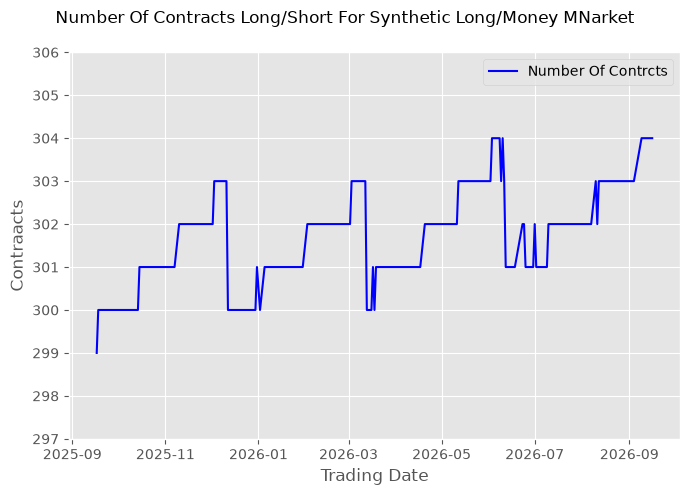

In [24]:
sp500=fred_data.get_series('SP500',start_date='2025-09-16',end_date='2026-09-16')
wr_synthetic=(1+df_calibration['Futures_Return']+df_calibration['Daily_SOFR_Yield']).cumprod()
wr_sp500=sp500['SP500']/sp500['SP500'].iloc[0]
df=pd.concat([wr_synthetic,wr_sp500],axis=1,join='inner')
df.rename(columns={0:'wr_synthetic','SP500':'wr_sp500'},inplace=True)
df['Num Contracts']=round(302.72*df['wr_synthetic']/df['wr_sp500']*df_calibration['Financing_Scalar'])

# 1. Define data to be plotted
plot_data=[df['Num Contracts']]


# 2. Define the series
series=['Number Of Contrcts']

# 3. x_axis dates
x_axis=df['Num Contracts'].index

size=(7,5)
markers=['']
colors=['b']

# use nanmin and nanmax so that nan is ignogred
y_lower=plot_data[0].min()-2
y_upper=plot_data[0].max()+2


ylim=[y_lower,y_upper]
title='Number Of Contracts Long/Short For Synthetic Long/Money MNarket'
xlabel='Trading Date'
ylabel='Contraacts'
fq.one_y_axis(x_axis, plot_data, title=title, series_labels=series, xlabel=xlabel,
              y_limits=ylim,ylabel=ylabel, markers=markers,colors=colors,
              figure_size=size)

## 🏗️ Constructing and Evaluating the Synthetic Portfolios
To see the real-world impact of the arbitrage bands and contract rounding, we must translate our daily rates and contract sizes into cumulative dollar values. We will track a \$100,000,000 initial investment across four distinct portfolios to isolate the exact tracking error caused by market frictions.

* **The Baselines (Actual Markets):** We calculate the baseline growth of \$100M invested purely in the at daily SOFR and \$100M invested purely in the S&P 500 Total Return Index.

* **The Synthetic Long:** We combine the compounding SOFR cash balance with the daily mark-to-market P&L of our long futures position.

* **The Synthetic Money Market:** Leveraging our earlier realization, we take the compounding S&P 500 cash balance and subtract the long futures P&L (synthetically shorting the futures) to strip out the equity risk.

* **The Excess Returns (Tracking Error):** By subtracting the actual baselines from our synthetic portfolios, we isolate the cumulative dollar impact of the futures basis drifting rich or cheap over the life of the trade. As mathematically expected, the excess return of the synthetic long will perfectly mirror the excess return of the synthetic money market.

>**Crucial Note on Dynamic Sizing:** It is important to highlight that our `Num Contracts` calculation dynamically hedges the current wandering portfolio value ($V_t$), rather than remaining statically pegged to the initial $100M. Because we continuously adjust the hedge ratio, the excess return is systematically reined in. In the strong upward-trending market of our sample period, constantly resizing the contract overlay to match the growing portfolio value actually diminishes the cumulative excess return compared to simply holding a static number of contracts.

In the code block below, we will calculate these cumulative values and immediately plot the results so we can visually compare the absolute portfolio growth alongside the mirrored tracking errors.

:::{dropdown}<b>📝 The Code Below Uses Pandas `cumsum()` method: Here Is An example</b>
<br>
The `cumsum()` method calculates the cumulative value of adding the values of a series. We use to calculate the total value of future gains. Below is a simple example you can try.

```python
import pandas as pd
# 1. Create a simple list of daily cash flows
cash_flows = pd.Series([100, 50, -20, 30])

# 2. Apply the cumsum() method
running_balance = cash_flows.cumsum()

# 3. Print the results
print("Daily Cash Flows:")
print(cash_flows.tolist())

print("\nRunning Balance (Cumulative Sum):")
print(running_balance.tolist())
```
Daily Cash Flows:
[100, 50, -20, 30]

Running Balance (Cumulative Sum):
[100, 150, 130, 160]

:::


In [25]:
import pandas as pd
import altair as alt

# 1. Calculate the daily mark-to-market P&L of the futures overlay
total_future_gains = (df_calibration['F_diff'] * 50 * df['Num Contracts']).cumsum()

# 2. Calculate the baseline cumulative values
money_market_value = (1 + df_calibration['Daily_SOFR_Yield']).cumprod() * 100_000_000
cash_value = (1 + df_calibration['SPTR_return']).cumprod() * 100_000_000

# 3. Construct the Synthetic Portfolios
synth_long_value = total_future_gains + money_market_value
synth_money_market_value = cash_value - total_future_gains

# 4. Calculate Excess Returns
excess_synth_long_value = synth_long_value - cash_value
excess_synth_money_market_value = synth_money_market_value - money_market_value

# 5. Prepare Data for Altair
df_plot = pd.DataFrame({
    'Date': df_calibration.index,
    'Actual S&P 500': cash_value,
    'Synthetic Long': synth_long_value,
    'Synthetic Long Excess': excess_synth_long_value,
    'Actual SOFR': money_market_value,
    'Synthetic Money Market': synth_money_market_value,
    'Synthetic Money Market Excess': excess_synth_money_market_value
})

# Zero line for excess return charts
zero_line = alt.Chart(pd.DataFrame({'y': [0]})).mark_rule(color='black', strokeDash=[3,3], opacity=0.5).encode(y='y:Q')

# --- ROW 1: SYNTHETIC LONG DASHBOARD ---
df_long_abs = df_plot.melt(id_vars=['Date'], value_vars=['Actual S&P 500', 'Synthetic Long'], var_name='Portfolio', value_name='Value')

chart_long_abs = alt.Chart(df_long_abs).mark_line().encode(
    x='Date:T',
    y=alt.Y('Value:Q', scale=alt.Scale(zero=False), title='Portfolio Value ($)'),
    color=alt.Color('Portfolio:N', scale=alt.Scale(domain=['Actual S&P 500', 'Synthetic Long'], range=['#FF5722', 'blue']), legend=alt.Legend(title="Long Portfolio")),
    strokeWidth=alt.condition(alt.datum.Portfolio == 'Actual S&P 500', alt.value(6), alt.value(2))
).properties(width=350, height=250, title='Synthetic Long vs Actual S&P 500')

chart_long_excess = alt.Chart(df_plot).mark_line(color='green').encode(
    x='Date:T',
    y=alt.Y('Synthetic Long Excess:Q', title='Excess Value ($)')
).properties(width=350, height=250, title='Long Tracking Error') + zero_line


# --- ROW 2: SYNTHETIC MONEY MARKET DASHBOARD ---
df_mm_abs = df_plot.melt(id_vars=['Date'], value_vars=['Actual SOFR', 'Synthetic Money Market'], var_name='Portfolio', value_name='Value')

chart_mm_abs = alt.Chart(df_mm_abs).mark_line().encode(
    x='Date:T',
    y=alt.Y('Value:Q', scale=alt.Scale(zero=False), title='Portfolio Value ($)'),
    color=alt.Color('Portfolio:N', scale=alt.Scale(domain=['Actual SOFR', 'Synthetic Money Market'], range=['#FF5722', 'purple']), legend=alt.Legend(title="Cash Portfolio")),
    strokeWidth=alt.condition(alt.datum.Portfolio == 'Actual SOFR', alt.value(6), alt.value(2))
).properties(width=350, height=250, title='Synthetic Money Market vs Actual SOFR')

chart_mm_excess = alt.Chart(df_plot).mark_line(color='red').encode(
    x='Date:T',
    y=alt.Y('Synthetic Money Market Excess:Q', title='Excess Value ($)')
).properties(width=350, height=250, title='Money Market Tracking Error') + zero_line

# 6. Combine all charts into a 2x2 grid
dashboard = (
    (chart_long_abs | chart_long_excess).resolve_scale(color='independent') &
    (chart_mm_abs | chart_mm_excess).resolve_scale(color='independent')
).configure_title(fontSize=14)

dashboard

alt.VConcatChart(...)

## 🪞 Decoding the Dashboards: The Mirror Effect and Path Dependency
1. **The Zero-Sum Mirror:**
The most obvious and important takeaway from the tracking error charts is the perfect symmetry. The synthetic long excess returns are the exact mathematical opposite of the synthetic money market excess returns. This visually demonstrates the zero-sum nature of arbitrage: any basis premium that causes the synthetic long portfolio to bleed performance (a loss) is simultaneously captured as excess yield (a gain) by the synthetic money market.

2. **The Path-Dependency of Excess Returns (39.6 bps vs. 32 bps):**
If you recall our earlier, simpler calculations where we "locked in" gains on a static notional value, the excess return appeared to be roughly 36 basis points. Our dynamic cumulative portfolio, however, shows a tighter excess return of slightly over 32 basis points. Why did the yield shrink? The answer is dynamic sizing effects.

    * The extra yield in the static calculation was not truly "riskless" arbitrage—it was path-dependent. Because the arbitrage band made futures rich in the third quarter (the September contract), the increased number of contracts purchased with the gains from the second quarter actually magnified the drag in the third quarter.

    * By dynamically recalculating the rounded number of contracts against the moving portfolio value every day, the results reflect the full impact of the arbitrage bands dynamics.


## The Next Objective: 🪙 Rigging the Toss: From Static to Dynamic

You may have heard of the 60/40 rule. The rule basically says that 40 to 60% of your capital should be invested in stocks and the residual in bonds. The idea is to put the brakes on market timing and risk. There is a related concept called portfolio insurance. It can live within the 60/40 rule, but it also takes a more active look at the amount that is safe and what is at risk. Here we will consider a heuristic version of portfolio insurance—something that protects a base level of investment but expands risk when the base is safe.

### 🧭 The Heuristic Rule
As in our previous example, we'll assume a \$100 million initial investment that we want to ensure doesn't fall below \$80 million in value over the next year. There are, of course, some very obvious and bland ways to achieve that result, but our intent here is to capture the upside of risk while limiting the downside. Following up on our synthetic long example, we want to convert a money market investment into a synthetic S&P 500 investment, but do it in a dynamic way that protects our \$80 million minimum.

The rule we'll follow is called **Constant Proportion Portfolio Insurance (CPPI)**. The four moving parts of the rule are:

1. **The Floor:** The minimum value of the portfolio.
2. **The Time Horizon:** The period of time the minimum value is protected.
3. **Cushion:** The amount the current value of the portfolio exceeds the floor.
4. **Multiplier:** The amount of money invested in the risky asset equals the multiplier times the cushion.

In our example, the minimum value is 80% of the initial investmnt or \$80 million. The time horizon is one year and the multiplier is three. Because the cushion is \$20 million, our investment in the S&P 500 is \$60 million. We are following the 60/40 rule.

Before we look at results, let's keep a couple things in mind.

* **The Buy/Sell Sequence:** We are buying when prices go up and selling when they go down. You might know this as a momentum trade—a strategy that works when prices are trending. But what happens when they are bouncing around? There are a lot of wasted trades—buying and then selling as the price bounces within a range. We've identified this as information versus noise trades. You don't expect the trend to correct, but noise trading ebbs and flows as noise and therefore is ephemeral.

* **Strategy Drains Liquidity:** Because the strategy trades according to the direction of prices, it reduces the liquidity of the market. The more practitioners, the more difficult the strategy is to execute. As we'll note later, this flaw is a substantial drawback.



### ⚙️ Implementing The Rule
The code below implements our version of CPPI rule. After establishing the parameters of the rule, we loop through futures gains and update the value of the portfolio and adjust the contracts for each day.

Once the daily contract targets are set, we calculate the total trading volume and the direction of those trades. If a trade reverses the direction of our last active trade (ignoring days where no contracts were bought or sold), we classify it as "noise" (a whipsaw trade) and assign a binary flag (1 or 0) to highlight these wasted trades in our dashboard.

In [27]:
# --- 1. Define the Synthetic CPPI Rules (Matching the $100M Example) ---
initial_wealth = 100_000_000  # $100 million initial investment
floor_percentage = 0.80       # Protects the $80 million minimum (The Floor)
multiplier = 3.0              # Multiplier for the risky asset allocation
contract_multiplier = 50      # S&P 500 E-mini fixed multiplier

# Initialize NumPy arrays to efficiently store our daily tracking metrics
synth_cppi_wealth = np.zeros(len(df_calibration))
target_exposure_log = np.zeros(len(df_calibration))
contracts_held = np.zeros(len(df_calibration))
futures_pnl_log = np.zeros(len(df_calibration))

# Initial State setup
current_wealth = initial_wealth
floor_value = initial_wealth * floor_percentage

# Day 0 Target Exposure
cushion = max(current_wealth - floor_value, 0) # Amount current value exceeds the floor
target_exposure = min(cushion * multiplier, current_wealth) # Cushion x Multiplier

# Extract Numpy arrays for the loop (Assuming settlement_price and f_diff are in df_calibration)
sofr_yields = df_calibration['Daily_SOFR_Yield'].values
f_diff = df_calibration['F_diff'].values
f_price = df_calibration['settlement_price'].values

# Calculate Day 0 Contracts (This establishes our initial 60% exposure)
current_contracts = np.round(target_exposure / (f_price[0] * contract_multiplier))

# --- 2. Run the Synthetic Daily Simulation ---
for i in range(len(df_calibration)):

    # A. Calculate today's Futures P&L based on yesterday's held contracts
    daily_futures_pnl = current_contracts * f_diff[i] * contract_multiplier

    # B. Apply Returns: The base investment earns SOFR, overlaid with the futures P&L
    current_wealth = (current_wealth * (1 + sofr_yields[i])) + daily_futures_pnl

    # C. Calculate the New CPPI Target based on updated wealth
    cushion = max(current_wealth - floor_value, 0)
    target_exposure = min(cushion * multiplier, current_wealth)

    # D. Update Contracts based on the new target and today's closing futures price
    # This executes the "Buy/Sell Sequence": buying as prices/wealth rise, selling as they fall
    current_contracts = np.round(target_exposure / (f_price[i] * contract_multiplier))

    # E. Log the daily data
    synth_cppi_wealth[i] = current_wealth
    target_exposure_log[i] = target_exposure
    contracts_held[i] = current_contracts
    futures_pnl_log[i] = daily_futures_pnl

# --- 3. Save to DataFrame ---
df_plot['Dynamic Contracts Held']=contracts_held

# Calculate the daily trading volume (difference between today's and yesterday's contracts)
df_plot['Contract Trades'] = df_plot['Dynamic Contracts Held'].diff().fillna(0)

# Get the direction of the trade (+1 for buy, -1 for sell, 0 for no trade)
current_trade_sign = np.sign(df_plot['Contract Trades'])
previous_trade_sign = np.sign(df_plot['Contract Trades'].shift(1))

# Flag is 1 if a trade occurred AND it is the opposite direction of the previous trade
df_plot['Synth Whipsaw Flag'] = np.where(
    (current_trade_sign != 0) & (current_trade_sign == -previous_trade_sign),
    1,
    0
)
df_plot['Synthetic CPPI Value'] = synth_cppi_wealth
df_plot['Dynamic Contracts Held'] = contracts_held
df_plot['Futures P&L ($)'] = futures_pnl_log

## 🔍 Visualizing the Details: A Four-Level Diagnostic

We can now visualize exactly how this heuristic strategy behaves between September 17, 2025, and September 16, 2026.

The following dashboard divides the behavior into two distinct timeframes to contrast the overarching performance of the strategy against its daily mechanical reality:

**Levels 1 & 2 (The Macro View):** The top half tracks the entire lifecycle of the trade. On the left of Level 1 is a comparison of the portfolio to the S&P 500. The left of Level 2 shows the total number of S&P E-mini contracts (our long S&P 500 exposure). On the right, we plot the daily trading volume. All the trades are shown in blue on Level 1, and those designated as 'noise' trades are in red on Level 2.

**Levels 3 & 4 (The Micro View):** The bottom half zooms in on a specific 30-day window (August 17 to September 16, 2026). During this period, the portfolio has built a massive safety cushion above our absolute floor. You might expect that cushion would imply very little trading.

As you review the charts, pay close attention to the right side of the dashboard. The red bars are the instances where the rule buys high and sells low. When judging the frequency of trading on levels three and four, be mindful that the x-axis only covers one month. There are both fewer days and trades than levels 1 and 2.

In [28]:


# --- 1. Data Preparation ---
# Macro Data
df_synth_wealth = df_plot.melt(
    id_vars=['Date'],
    value_vars=['Actual S&P 500', 'Synthetic CPPI Value'],
    var_name='Strategy',
    value_name='Portfolio Value'
)

# Micro Data (Zoomed Window)
start_date = pd.to_datetime('2026-08-17')
end_date = pd.to_datetime('2026-09-16')
df_zoom = df_plot[(df_plot['Date'] >= start_date) & (df_plot['Date'] <= end_date)]
df_zoom_wealth = df_synth_wealth[(df_synth_wealth['Date'] >= start_date) & (df_synth_wealth['Date'] <= end_date)]

# Standardized chart dimensions
w, h = 350, 160

# --- LEVEL 1: MACRO OUTCOME ---
chart_perf_macro = alt.Chart(df_synth_wealth).mark_line().encode(
    x=alt.X('Date:T', axis=alt.Axis(title='', labels=False)),
    y=alt.Y('Portfolio Value:Q', scale=alt.Scale(zero=False), title='Value ($)'),
    color=alt.Color('Strategy:N', scale=alt.Scale(domain=['Actual S&P 500', 'Synthetic CPPI Value'], range=['#d3d3d3', 'darkorange']), legend=alt.Legend(title="Portfolio")),
    strokeWidth=alt.condition(alt.datum.Strategy == 'Actual S&P 500', alt.value(5), alt.value(2))
).properties(width=w, height=h, title='Level 1: Macro Performance vs Unhedged')

chart_vol_macro = alt.Chart(df_plot).mark_bar(color='steelblue', size=1.5).encode(
    x=alt.X('Date:T', axis=alt.Axis(title='', labels=False)),
    y=alt.Y('Contract Trades:Q', title='Contracts Traded')
).properties(width=w, height=h, title='Level 1: Macro Trading Volume (Unfiltered)')

# --- LEVEL 2: MACRO AUTOPSY ---
chart_delta_macro = alt.Chart(df_plot).mark_area(opacity=0.3, color='blue').encode(
    x=alt.X('Date:T', axis=alt.Axis(title='', labels=False)),
    y=alt.Y('Dynamic Contracts Held:Q', title='Total Contracts')
).properties(width=w, height=h, title='Level 2: Macro Replicating Delta (Total Contracts)')

chart_noise_macro = alt.Chart(df_plot).mark_bar(color='red', size=1.5).encode(
    x=alt.X('Date:T', axis=alt.Axis(title='', labels=False)),
    y=alt.Y('Contract Trades:Q', title='Contracts Traded')
).transform_filter(alt.datum['Synth Whipsaw Flag'] == 1).properties(width=w, height=h, title='Level 2: Macro Whipsaw Tax (Noise ONLY)')

# --- LEVEL 3: MICRO OUTCOME (Aug 17 - Sep 16) ---
chart_perf_micro = alt.Chart(df_zoom_wealth).mark_line().encode(
    x=alt.X('Date:T', axis=alt.Axis(title='', labels=False)),
    y=alt.Y('Portfolio Value:Q', scale=alt.Scale(zero=False), title='Value ($)'),
    color=alt.Color('Strategy:N', scale=alt.Scale(domain=['Actual S&P 500', 'Synthetic CPPI Value'], range=['#d3d3d3', 'darkorange']), legend=None),
    strokeWidth=alt.condition(alt.datum.Strategy == 'Actual S&P 500', alt.value(5), alt.value(2))
).properties(width=w, height=h, title='Level 3: Micro Performance (The $37M Cushion)')

chart_vol_micro = alt.Chart(df_zoom).mark_bar(color='steelblue', size=4).encode(
    x=alt.X('Date:T', axis=alt.Axis(title='', labels=False)),
    y=alt.Y('Contract Trades:Q', title='Contracts Traded')
).properties(width=w, height=h, title='Level 3: Micro Trading Volume')

# --- LEVEL 4: MICRO AUTOPSY (Aug 17 - Sep 16) ---
chart_delta_micro = alt.Chart(df_zoom).mark_area(opacity=0.3, color='blue').encode(
    x=alt.X('Date:T', title='Date'),
    y=alt.Y('Dynamic Contracts Held:Q', scale=alt.Scale(zero=False), title='Total Contracts')
).properties(width=w, height=h, title='Level 4: Micro Real Delta Needed')

chart_noise_micro = alt.Chart(df_zoom).mark_bar(color='red', size=4).encode(
    x=alt.X('Date:T', title='Date'),
    y=alt.Y('Contract Trades:Q', title='Contracts Traded')
).transform_filter(alt.datum['Synth Whipsaw Flag'] == 1).properties(width=w, height=h, title='Level 4: Micro Wasted Trades (Noise ONLY)')

# --- ASSEMBLE THE 4-LEVEL DASHBOARD ---
level_1 = chart_perf_macro | chart_vol_macro
level_2 = chart_delta_macro | chart_noise_macro
level_3 = chart_perf_micro | chart_vol_micro
level_4 = chart_delta_micro | chart_noise_micro

master_dashboard = (level_1 & level_2 & level_3 & level_4).resolve_scale(color='independent')
master_dashboard

alt.VConcatChart(...)

## 📝 The Anatomy of a Flawed Strategy: Macro to Micro
Our four-level dashboard exposes the inescapable mathematical trap of DIY dynamic hedging.

**Levels 1 & 2: The Macro Illusion and the Synthetic Trap**

At the macro level, the algorithm looks like it is working hard. Level 1 shows our performance lagging the market as we execute a massive amount of unfiltered trading volume.

Level 2 holds a critical realization of this exercise. By using synthetic futures, we completely eliminated the massive physical transaction costs of buying and selling underlying stocks. You might hope that this efficiency makes our "free" portfolio insurance work. It doesn't. Futures eliminate the execution friction, but they do absolutely nothing to fix the underlying path-dependency.

The red bars in Level 2 prove that the mechanical "buy-high, sell-low" whipsaw tax is a permanent feature of the algorithm. A noise trade in the futures market still bleeds portfolio alpha.

**Levels 3 & 4: The Micro Absurdity (Aug 17 - Sep 16)**

To understand just how inefficient this is, look at the bottom half of the dashboard, where we zoom in on the final month of trading.

By this point, our portfolio value has grown, giving us a massive $37 million cushion above our hard floor. We are miles away from the danger zone.

Yet, look at Level 4. The **Real Delta Needed (bottom left)** is completely flat. The structural need for downside protection hasn't changed. But look at the **Wasted Trades** (bottom right). Despite having a $37M cushion and a stable delta requirement, the algorithm is ruthlessly firing off red reversal trades.

**What is the efficacy of these trades?** Zero. They provide no meaningful downside protection. They only serve to burn liquidity and lock in mechanical losses because the algorithm cannot distinguish between a structural market breakdown and meaningless daily vibrations.

You cannot escape this paradox. Tight rebalancing bands bleed you to death via whipsaws. Loose rebalancing bands expose you to massive gap-risk during a crash.

## 🕰️ A Trip Down Memory Lane: 1987 and the Illusion of Infinite Liquidity
The heuristic simulation you just ran is not just an academic exercise—it was the foundation of the dominant risk management paradigm of the mid-1980s, heavily utilized by institutional investors under the name "Portfolio Insurance."

The underlying continuous-time models of that era were mathematically breathtaking. Notwithstanding their brilliance, they relied on a fragile assumption: frictionless and unbounded liquidity. The math assumed that no matter how fast the market fell, you would always be able to execute your dynamically adjusted "sell" orders at the next tick to protect your cushion. We just used a lot of brain cells to demonstrate the endogenous nature of liquidity.

In October 1987, reality broke the models. As the market started to drop, every institutional computer running portfolio insurance models generated automatic sell orders at more or less the same time. But there were no buyers on the other side. The assumption of infinite liquidity vanished. The mechanical, forced selling overwhelmed the structural capacity of the market, causing a cascading feedback loop that culminated in Black Monday—a 22.6% single-day drop in the Dow Jones.

**The Lesson:** Continuous dynamic hedging works beautifully on a chalkboard. But in the real world, liquidity is a finite resource.

## ⏭️ Coming Up In The Next Volume: The Option Pricing Solution
In the next volume, we will explore how to solve this exact problem using derivatives.

As we just saw, our mechanical CPPI rule was completely blind to time and probability. It ruthlessly traded the noise and bled alpha even when we had a massive cushion and only a month to go—a scenario where common sense dictates you shouldn't be trading at all.

If building your own dynamic hedge is this structurally flawed, the logical answer is to outsource it: you buy a put option and transfer the risk to a dealer. You pay a fixed premium upfront, you lock your absolute floor in place, and you sleep soundly.

But here is the ultimate market paradox: risk doesn't disappear; it only changes hands.

How does the dealer hedge the option they just sold you? They have to dynamically delta-hedge. Their implicit hedge is entirely path-dependent, exposing them to the exact same whipsawing, liquidity-draining nightmare we just used a lot of brain cells to simulate.

If you are handing a dealer a mathematically guaranteed headache, how much should they charge you to take it? And how does their hedging algorithm know how to factor in time and cushion so it stops trading the noise?

Enter Fischer Black, Myron Scholes, and the birth of modern option pricing.